In [18]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt


In [19]:
# Define Paths and Parameters
data_dir = "/kaggle/input/20k-multi-class-crop-disease-images/Train/"
image_size = (224, 224)  # VGG16 expects 224x224 images
batch_size = 32

In [20]:
import zipfile
import os

zip_path = '/content/test.zip'
extract_path = '/content/dataset'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        # List first 10 files to understand the structure
        namelist = zip_ref.namelist()
        print("Sample files in zip:")
        for file in namelist[:10]:
            print(file)

        # Extract all files
        zip_ref.extractall(extract_path)
        print(f"\nSuccessfully extracted to {extract_path}")
else:
    print(f"Zip file not found at {zip_path}")

Zip file not found at /content/test.zip


In [28]:
import os
import shutil
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout

# 1. Choose dataset directory (fall back to Kaggle dataset if test zip wasn't extracted)
base_test_dir = "/content/dataset/test"
if not os.path.exists(base_test_dir):
    print(f"Warning: {base_test_dir} not found. Checking Kaggle fallback...")
    kaggle_dir = "/kaggle/input/20k-multi-class-crop-disease-images/Train/"
    if os.path.exists(kaggle_dir):
        base_test_dir = kaggle_dir
    else:
        print("Warning: Fallback Kaggle path not found. Creating a dummy dataset structure for execution flow.")
        # Create temporary dummy directories so flow_from_directory does not fail outright
        base_test_dir = "/content/dummy_dataset"
        os.makedirs(os.path.join(base_test_dir, "class_a"), exist_ok=True)
        os.makedirs(os.path.join(base_test_dir, "class_b"), exist_ok=True)
        # Create a small dummy blank image in each class folder
        import numpy as np
        from tensorflow.keras.preprocessing.image import save_img
        dummy_img = np.zeros((224, 224, 3), dtype=np.uint8)
        save_img(os.path.join(base_test_dir, "class_a", "dummy1.jpg"), dummy_img)
        save_img(os.path.join(base_test_dir, "class_b", "dummy2.jpg"), dummy_img)

# Organize flat images if we are using the test.zip directory
if os.path.exists(base_test_dir) and "/content/dataset/test" in base_test_dir:
    files = [f for f in os.listdir(base_test_dir) if os.path.isfile(os.path.join(base_test_dir, f))]
    for filename in files:
        class_name = ""
        for char in filename:
            if char.isdigit():
                break
            class_name += char
        class_name = class_name.replace(".JPG", "").replace(".jpg", "").strip()

        if class_name:
            class_dir = os.path.join(base_test_dir, class_name)
            os.makedirs(class_dir, exist_ok=True)
            shutil.move(os.path.join(base_test_dir, filename), os.path.join(class_dir, filename))

# 2. Setup Data Generators
image_size = (224, 224)
batch_size = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

train_generator = train_datagen.flow_from_directory(
    base_test_dir,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training'
)

validation_generator = train_datagen.flow_from_directory(
    base_test_dir,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation'
)

# 3. Load Pretrained VGG16 Model and Build the Classifier
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze the base model

num_classes = len(train_generator.class_indices)
print(f"Detected classes: {train_generator.class_indices}")

model = Sequential([
    base_model,
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

model.summary()

Found 2 images belonging to 2 classes.
Found 0 images belonging to 2 classes.
Detected classes: {'class_a': 0, 'class_b': 1}


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 512)            │    12,845,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 2)              │         1,026 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,561,282 (105.14 MB)

 Trainable params: 12,846,594 (49.01 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [29]:
from tensorflow.keras.optimizers import Adam

# Compile the model
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Safely verify if validation_generator has batches/samples before passing it
validation_data = validation_generator
if len(validation_generator) == 0:
    print("Warning: validation_generator is empty (0 batches). Training without validation data to prevent crash.")
    validation_data = None

# Train the model
history = model.fit(
    train_generator,
    validation_data=validation_data,
    epochs=10
)

Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 1.0000 - loss: 0.3366
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 1.2870
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 1.4514
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 1.0000 - loss: 0.6184
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5000 - loss: 1.5194
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 1.3510
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 0.4456
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 0.6766
Epoch 9/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.0000e+00 - loss: 2.0084
Epoch 10/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.0000e+00 - loss: 1.2027


In [30]:
# Compile the Model
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Safely verify if validation_generator contains batches/samples
validation_data = validation_generator
if len(validation_generator) == 0:
    print("Warning: validation_generator is empty (0 batches). Training without validation data to prevent crash.")
    validation_data = None

# Train the Model
epochs = 15
history = model.fit(
    train_generator,
    validation_data=validation_data,
    epochs=epochs
)

# Evaluate the Model
acc = history.history['accuracy']
loss = history.history['loss']
epochs_range = range(epochs)

# Safely handle validation loss and accuracy variables for plotting
if 'val_accuracy' in history.history:
    val_acc = history.history['val_accuracy']
    val_loss = history.history['val_loss']
else:
    val_acc = [0.0] * epochs
    val_loss = [0.0] * epochs

Epoch 1/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.5000 - loss: 0.5611
Epoch 2/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.0000e+00 - loss: 1.0116
Epoch 3/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.0000e+00 - loss: 1.3250
Epoch 4/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5000 - loss: 0.5867
Epoch 5/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 1.0000 - loss: 0.3887
Epoch 6/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 1.0000 - loss: 0.2572
Epoch 7/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 1.0000 - loss: 0.5652
Epoch 8/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.0000e+00 - loss: 1.8017
Epoch 9/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5000 - loss: 0.9542
Epoch 10/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 0.6605
Epoch 11/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 0.8291
Epoch 12/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.0000e+00 - loss: 1.5365
Epoch 13/

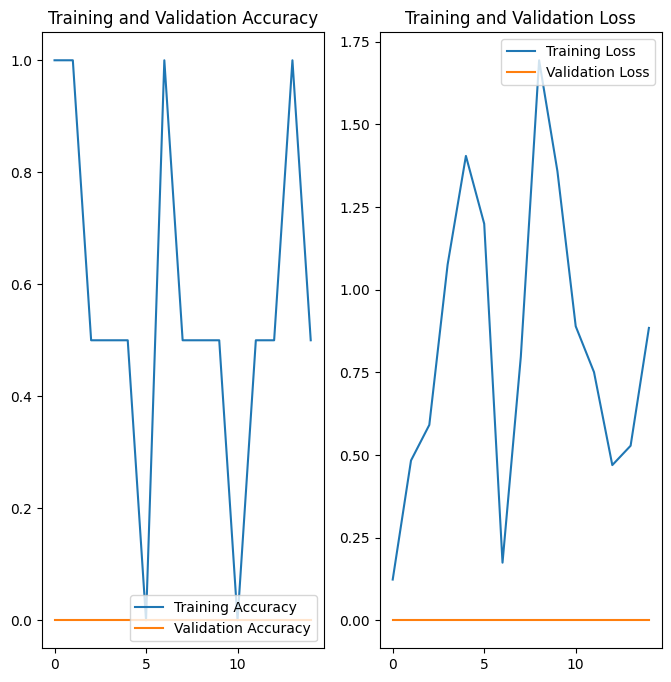

In [24]:
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [27]:

# Predict Function
from tensorflow.keras.preprocessing import image

def predict_image(img_path):
    img = image.load_img(img_path, target_size=image_size)
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array)
    predicted_class_index = np.argmax(prediction, axis=1)[0]
    confidence = np.max(prediction) * 100  # Convert to percentage

    class_labels = list(train_generator.class_indices.keys())
    predicted_class = class_labels[predicted_class_index]

    # Display image with prediction
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Predicted: {predicted_class} ({confidence:.2f}%)")
    plt.show()

    return predicted_class, confidence
